# Bank campaign

A bank wants to know, before the call, whether a customer will subscribe to a term deposit.

The table is the UCI Bank Marketing set: about 41,000 calls from May 2008 to November 2010. The rows are already in campaign order. Run the cells from top to bottom. Each cell does one thing.

```
bank-additional-full.csv -> train -> model.joblib -> app.py -> image -> container
```


## 1. Read the data

The separator is a semicolon. One row is one phone call. `y` says whether the customer subscribed.


In [28]:
import pandas as pd

df = pd.read_csv("data/bank-additional-full.csv", sep=";")
df.shape


(41188, 21)

In [29]:
df.head()


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [30]:
# 'duration' sütununu ve hedef değişkeni 'y'yi ayırıyoruz
X = df.drop(columns=["duration", "y"])

# 'yes' olanlar 1, 'no' olanlar 0 yapılır
y = (df["y"] == "yes").astype(int)

print("X boyutu (Girdiler):", X.shape)
print("Hedef Sınıf Dağılımı (y):")
print(y.value_counts())

X boyutu (Girdiler): (41188, 19)
Hedef Sınıf Dağılımı (y):
y
0    36548
1     4640
Name: count, dtype: int64


In [31]:
# Sayısal ve kategorik sütun isimlerini otomatik seçiyoruz
numeric_cols = X.select_dtypes(include="number").columns.tolist()
category_cols = X.select_dtypes(exclude="number").columns.tolist()

print("Sayısal Sütunlar:", numeric_cols)
print("Kategorik Sütunlar:", category_cols)

Sayısal Sütunlar: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Kategorik Sütunlar: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


## 2. EDA

Check empty cells, the `unknown` answers, and how many customers subscribed.


In [32]:
df.isna().sum()


age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

In [33]:
unknown = (df == "unknown").sum()
unknown[unknown > 0].sort_values(ascending=False)


default      8597
education    1731
housing       990
loan          990
job           330
marital        80
dtype: int64

In [34]:
df["y"].value_counts()


y
no     36548
yes     4640
Name: count, dtype: int64

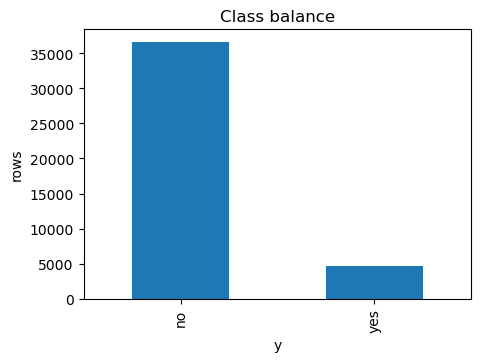

In [35]:
import matplotlib.pyplot as plt

%matplotlib inline

df["y"].value_counts().plot.bar(title="Class balance", ylabel="rows", figsize=(5, 3.5))
plt.show()  # Grafiği ekrana çizmeye zorlar

Subscription rate by job. Students and retired customers subscribe more often than the other jobs.


In [36]:
rate_by_job = (df["y"] == "yes").groupby(df["job"]).mean().sort_values()
rate_by_job


job
blue-collar      0.068943
services         0.081381
entrepreneur     0.085165
housemaid        0.100000
self-employed    0.104856
technician       0.108260
unknown          0.112121
management       0.112175
admin.           0.129726
unemployed       0.142012
retired          0.252326
student          0.314286
Name: y, dtype: float64

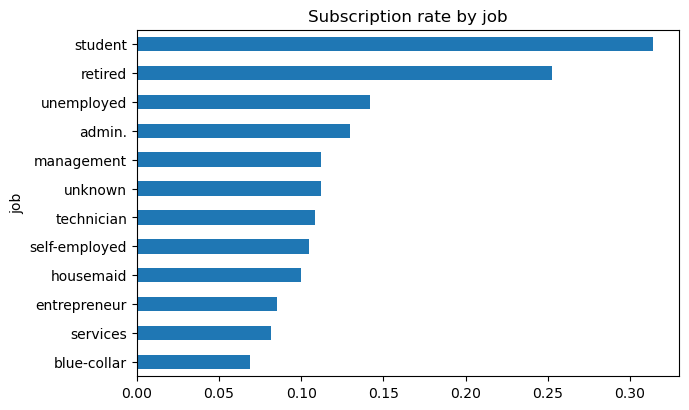

In [37]:
import matplotlib.pyplot as plt

# Yatay çubuk grafik (barh) olarak çizdiriyoruz ve plt.show() ekliyoruz
rate_by_job.plot.barh(
    title="Subscription rate by job", ylabel="job", figsize=(7, 4.5)
)
plt.show()

The file runs from May 2008 to November 2010. This is the subscription rate along that order.


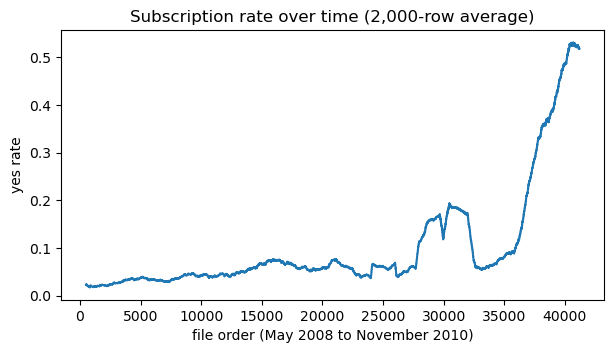

In [38]:
import matplotlib.pyplot as plt

%matplotlib inline

subscribed = (df["y"] == "yes").astype(float)
subscribed.rolling(2000, min_periods=500).mean().plot(
    title="Subscription rate over time (2,000-row average)",
    xlabel="file order (May 2008 to November 2010)",
    ylabel="yes rate",
    figsize=(7, 3.5),
)
plt.show() 

## 3. Preprocess

`duration` is the length of the call. The bank learns it only after the call ends, so the model does not get that column.


In [39]:
# 'duration' sızıntı yarattığı için düşürülür, hedef 'y' ayrılır
X = df.drop(columns=["duration", "y"])

# 'yes' -> 1, 'no' -> 0 yapılır
y = (df["y"] == "yes").astype(int)

print("X boyutu (Girdiler):", X.shape)
print("Sınıf Dağılımı (y):")
print(y.value_counts())

X boyutu (Girdiler): (41188, 19)
Sınıf Dağılımı (y):
y
0    36548
1     4640
Name: count, dtype: int64


The split follows the file. The first 70% train the model, the next 15% test it, and the last 15% are the live period. The live rows stay out of training and testing.


In [40]:
train_end = int(len(df) * 0.70)
test_end = int(len(df) * 0.85)

X_train = X.iloc[:train_end]
y_train = y.iloc[:train_end]
X_test = X.iloc[train_end:test_end]
y_test = y.iloc[train_end:test_end]
X_live = X.iloc[test_end:]
y_live = y.iloc[test_end:]

print("train", len(X_train))
print("test", len(X_test))
print("live", len(X_live))


train 28831
test 6178
live 6179


Numeric columns are scaled. Text columns are turned into 0/1 columns. Both steps are fit on the training rows only.


In [41]:
numeric_cols = X_train.select_dtypes(include="number").columns.tolist()
category_cols = X_train.select_dtypes(exclude="number").columns.tolist()
numeric_cols


['age',
 'campaign',
 'pdays',
 'previous',
 'emp.var.rate',
 'cons.price.idx',
 'cons.conf.idx',
 'euribor3m',
 'nr.employed']

In [42]:
category_cols


['job',
 'marital',
 'education',
 'default',
 'housing',
 'loan',
 'contact',
 'month',
 'day_of_week',
 'poutcome']

In [43]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

model = Pipeline([
    ("prep", ColumnTransformer([
        ("numbers", StandardScaler(), numeric_cols),
        ("categories", OneHotEncoder(handle_unknown="ignore"), category_cols),
    ])),
    ("model", LogisticRegression(max_iter=1000, C=0.1)),
])
model


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('numbers', StandardScaler(),
                                                  ['age', 'campaign', 'pdays',
                                                   'previous', 'emp.var.rate',
                                                   'cons.price.idx',
                                                   'cons.conf.idx', 'euribor3m',
                                                   'nr.employed']),
                                                 ('categories',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['job', 'marital',
                                                   'education', 'default',
                                                   'housing', 'loan', 'contact',
                                                   'month', 'day_of_week',
                                                   'poutcome'])])),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

In [46]:
import numpy as np
from sklearn.metrics import f1_score

validation_end = int(len(X_train) * 0.8)
X_fit, y_fit = X_train.iloc[:validation_end], y_train.iloc[:validation_end]
X_validation = X_train.iloc[validation_end:]
y_validation = y_train.iloc[validation_end:]

model.fit(X_fit, y_fit)
validation_probability = model.predict_proba(X_validation)[:, 1]
thresholds = np.linspace(0.05, 0.5, 91)
validation_f1 = [
    f1_score(y_validation, validation_probability >= threshold, zero_division=0)
    for threshold in thresholds
]
best_index = int(np.argmax(validation_f1))
decision_threshold = float(thresholds[best_index])
print("Validation F1:", round(validation_f1[best_index], 4))
print("Decision threshold:", round(decision_threshold, 3))


--- SINIFLANDIRMA RAPORU ---
              precision    recall  f1-score   support

          no       0.96      0.17      0.28      5520
         yes       0.12      0.94      0.21       658

    accuracy                           0.25      6178
   macro avg       0.54      0.55      0.25      6178
weighted avg       0.87      0.25      0.28      6178

ROC-AUC Skoru: 0.6608


## 4. Train

A validation slice from the end of the training period selects the probability threshold that gives the best F1. The model is then refit on all training rows; the test and live periods do not select the threshold.


In [47]:
model.fit(X_train, y_train)


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('numbers', StandardScaler(),
                                                  ['age', 'campaign', 'pdays',
                                                   'previous', 'emp.var.rate',
                                                   'cons.price.idx',
                                                   'cons.conf.idx', 'euribor3m',
                                                   'nr.employed']),
                                                 ('categories',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['job', 'marital',
                                                   'education', 'default',
                                                   'housing', 'loan', 'contact',
                                                   'month', 'day_of_week',
                                                   'poutcome'])])),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

In [48]:
import json
from pathlib import Path
import joblib

Path("serve").mkdir(exist_ok=True)
joblib.dump(model, "serve/model.joblib")
Path("serve/threshold.json").write_text(
    json.dumps({"threshold": decision_threshold}, indent=2) + "\n",
    encoding="utf-8",
)


['serve/model.joblib']

Save how the training rows are spread out. The live period will be compared with this snapshot.


In [49]:
import json
import numpy as np

reference = {"numeric": {}, "categorical": {}}

for name in numeric_cols:
    edges = np.unique(np.quantile(X_train[name], [i / 10 for i in range(11)]))
    if len(edges) == 1:
        edges = np.array([edges[0] - 1, edges[0] + 1])
    counts, _ = np.histogram(X_train[name], bins=edges)
    reference["numeric"][name] = {
        "edges": edges.tolist(),
        "share": (counts / counts.sum()).tolist(),
    }

for name in category_cols:
    share = X_train[name].astype(str).value_counts(normalize=True)
    reference["categorical"][name] = share.to_dict()

Path("serve/reference.json").write_text(json.dumps(reference))
print("numeric", len(reference["numeric"]), "categorical", len(reference["categorical"]))


numeric 9 categorical 10


## 5. Test

Score only the untouched test period. The threshold was selected on a validation slice within the training period. Read precision, recall, F1, accuracy, and ROC-AUC; ROC-AUC does not depend on the selected threshold. The second probability column is P(yes), because the labels are 0 and 1.


In [50]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

probability = model.predict_proba(X_test)[:, 1]
predicted = (probability >= decision_threshold).astype(int)


In [52]:
print(classification_report(y_test, predicted, target_names=["no", "yes"]))


              precision    recall  f1-score   support

          no       0.96      0.17      0.28      5520
         yes       0.12      0.94      0.21       658

    accuracy                           0.25      6178
   macro avg       0.54      0.55      0.25      6178
weighted avg       0.87      0.25      0.28      6178



In [53]:
pd.DataFrame(
    confusion_matrix(y_test, predicted),
    index=["actual no", "actual yes"],
    columns=["predicted no", "predicted yes"],
)


,predicted no,predicted yes
actual no,918,4602
actual yes,38,620


In [54]:
roc_auc_score(y_test, probability)


0.6607776089159068

## 6. Docker

The next cell writes the service. It loads the saved model, accepts one customer as JSON, and returns the probability of `yes`. Each request is appended to `logs/requests.jsonl`.

After these cells, from this folder, run these commands in PowerShell:

```powershell
docker build -t bank-campaign ./serve
New-Item -ItemType Directory -Force logs
docker run --rm -p 8000:8000 -v "${PWD}/logs:/logs" bank-campaign
```

Leave that terminal and the container running, then continue with the notebook. Stop it later with Ctrl+C.


In [55]:
Path("serve/app.py").write_text(r"""
import json
import os
from pathlib import Path

import joblib
import pandas as pd
from fastapi import FastAPI

model = joblib.load(Path(__file__).resolve().parent / "model.joblib")
threshold_data = json.loads(
    (Path(__file__).resolve().parent / "threshold.json").read_text(encoding="utf-8")
)
decision_threshold = float(threshold_data["threshold"])
if not 0 <= decision_threshold <= 1:
    raise ValueError("The saved decision threshold must be between 0 and 1.")
log_path = Path(os.environ.get("LOG_PATH", "/logs/requests.jsonl"))
app = FastAPI()

@app.get("/health")
def health():
    return {"status": "ok"}

@app.post("/predict")
def predict(row: dict):
    log_path.parent.mkdir(parents=True, exist_ok=True)
    with log_path.open("a") as handle:
        handle.write(json.dumps(row) + "\n")
    frame = pd.DataFrame([row])
    probability = float(model.predict_proba(frame)[0, 1])
    label = "yes" if probability >= decision_threshold else "no"
    return {"label": label, "probability": round(probability, 4)}
""".strip() + "\n")
print("wrote serve/app.py")


wrote serve/app.py


In [56]:
Path("serve/Dockerfile").write_text("""
FROM python:3.10-slim

WORKDIR /app

COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt

COPY app.py model.joblib threshold.json .

ENV LOG_PATH=/logs/requests.jsonl

EXPOSE 8000

CMD ["uvicorn", "app:app", "--host", "0.0.0.0", "--port", "8000"]
""".strip() + "\n")
print("wrote serve/Dockerfile")


wrote serve/Dockerfile


In [57]:
Path("serve/requirements.txt").write_text("""
fastapi==0.162.0
uvicorn==0.54.0
scikit-learn==1.7.2
joblib==1.6.0
pandas==2.3.3
""".strip() + "\n")
print("wrote serve/requirements.txt")


wrote serve/requirements.txt


## 7. Live inference and drift

Send every live-period customer to the service. Then compare those requests with the training snapshot.

PSI is a single number per column. Split the column into bins, and for each bin compute `(live share - train share) * log(live share / train share)`. Add the bins. Below 0.10 is stable, below 0.20 is a small shift, and 0.20 or above is drift.


In [58]:
import httpx

log_path = Path("logs/requests.jsonl")
log_path.parent.mkdir(exist_ok=True)
starting_line_count = (
    len(log_path.read_text(encoding="utf-8").splitlines()) if log_path.exists() else 0
)

rows = json.loads(X_live.to_json(orient="records"))
with httpx.Client(base_url="http://127.0.0.1:8000", timeout=30) as client:
    for i, row in enumerate(rows, start=1):
        response = client.post("/predict", json=row)
        response.raise_for_status()
        if i % 1000 == 0:
            print("sent", i)
print("sent", len(rows))


ConnectError: [WinError 10061] Hedef makine etkin olarak reddettiğinden bağlantı kurulamadı

In [27]:
request_lines = log_path.read_text(encoding="utf-8").splitlines()[starting_line_count:]
if len(request_lines) != len(X_live):
    raise ValueError(f"Expected {len(X_live)} new requests, found {len(request_lines)}.")
live_df = pd.DataFrame([json.loads(line) for line in request_lines if line.strip()])
live_df.head()


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
0,45,blue-collar,single,high.school,no,no,no,cellular,may,fri,1,999,0,nonexistent,-1.8,92.893,-46.2,1.25,5099.1
1,31,blue-collar,married,university.degree,no,yes,no,cellular,may,fri,1,999,0,nonexistent,-1.8,92.893,-46.2,1.25,5099.1
2,25,blue-collar,single,basic.9y,no,yes,no,cellular,may,fri,2,999,0,nonexistent,-1.8,92.893,-46.2,1.25,5099.1
3,55,management,married,basic.6y,unknown,no,yes,cellular,may,fri,1,999,0,nonexistent,-1.8,92.893,-46.2,1.25,5099.1
4,39,self-employed,married,basic.9y,no,yes,no,cellular,may,fri,1,999,0,nonexistent,-1.8,92.893,-46.2,1.25,5099.1


`euribor3m` is the interest rate. It fell from 2008 to 2010, so this column is a clear place to see the calculation.


In [28]:
name = "euribor3m"
edges = np.array(reference["numeric"][name]["edges"])
train_share = np.array(reference["numeric"][name]["share"], dtype=float)

live_values = np.clip(live_df[name].to_numpy(dtype=float), edges[0], edges[-1])
live_counts, _ = np.histogram(live_values, bins=edges)
live_share = live_counts / live_counts.sum()

train_share = np.clip(train_share, 1e-4, None)
live_share = np.clip(live_share, 1e-4, None)
train_share = train_share / train_share.sum()
live_share = live_share / live_share.sum()

euribor_psi = np.sum((live_share - train_share) * np.log(live_share / train_share))
float(euribor_psi)


8.484151523807324

The same sum for every column.


In [29]:
drift_rows = []

for name in reference["numeric"]:
    edges = np.array(reference["numeric"][name]["edges"])
    train_share = np.array(reference["numeric"][name]["share"], dtype=float)
    live_values = np.clip(live_df[name].to_numpy(dtype=float), edges[0], edges[-1])
    live_counts, _ = np.histogram(live_values, bins=edges)
    live_share = live_counts / live_counts.sum()

    train_share = np.clip(train_share, 1e-4, None)
    live_share = np.clip(live_share, 1e-4, None)
    train_share = train_share / train_share.sum()
    live_share = live_share / live_share.sum()
    score = float(np.sum((live_share - train_share) * np.log(live_share / train_share)))

    if score < 0.10:
        status = "stable"
    elif score < 0.20:
        status = "small shift"
    else:
        status = "drift"
    drift_rows.append({"feature": name, "psi": round(score, 3), "status": status})

for name in reference["categorical"]:
    train_share = pd.Series(reference["categorical"][name], dtype=float)
    live_share = live_df[name].astype(str).value_counts(normalize=True)
    categories = train_share.index.union(live_share.index)
    train_share = train_share.reindex(categories, fill_value=0).to_numpy()
    live_share = live_share.reindex(categories, fill_value=0).to_numpy()

    train_share = np.clip(train_share, 1e-4, None)
    live_share = np.clip(live_share, 1e-4, None)
    train_share = train_share / train_share.sum()
    live_share = live_share / live_share.sum()
    score = float(np.sum((live_share - train_share) * np.log(live_share / train_share)))

    if score < 0.10:
        status = "stable"
    elif score < 0.20:
        status = "small shift"
    else:
        status = "drift"
    drift_rows.append({"feature": name, "psi": round(score, 3), "status": status})

drift_table = pd.DataFrame(drift_rows).sort_values("psi", ascending=False)
drift_table


,feature,psi,status
4,emp.var.rate,11.517,drift
8,nr.employed,11.324,drift
7,euribor3m,8.484,drift
5,cons.price.idx,3.896,drift
6,cons.conf.idx,3.204,drift
18,poutcome,1.506,drift
16,month,1.385,drift
15,contact,0.654,drift
12,default,0.471,drift
9,job,0.469,drift
